# Notebook 03 — Topic modeling komentar (BERTopic, TK-3)

Bagian **tema** dari RQ2. Di TK-1, *topic modeling* dipakai untuk menemukan tema wacana, khususnya **tema kritik**,
tanpa kategori yang ditentukan lebih dulu. Notebook ini punya dua tahap:

- **A. Model umum** pada semua komentar eligible. Tahap ini tidak bergantung pada label siapa pun, menghasilkan peta tema,
  prevalensi per bulan, dan (bila prediksi sentimen Kania sudah ada) silang topik × sentimen.
- **B. Model terfokus** pada komentar yang diprediksi negatif. Tema kritik cenderung jarang dan beragam, sehingga di model umum
  mudah tenggelam ke topik besar atau ke *outlier*. Tahap B hanya berjalan bila file prediksi sentimen tersedia.

**Pemeriksaan yang sengaja ditambahkan** (karena *topic modeling* pada komentar pendek mudah menghasilkan topik semu):
1. **Dominasi satu video.** Komentar menanggapi videonya, jadi sebuah "topik" bisa saja hanya berarti "komentar di video X".
   Untuk tiap topik dihitung porsi dokumen dari video penyumbang terbesar.
2. **Teks berulang.** Klaster bisa terbentuk dari kalimat formulaik yang sama persis. Dihitung porsi teks unik per topik.
3. **Stabilitas.** Model dilatih ulang dengan *seed* UMAP lain; topik yang tidak muncul kembali ditandai.
4. **Coherence (NPMI) dan diversity** dipakai sebagai panduan memilih konfigurasi, bukan penentu tunggal, karena pada teks pendek
   keduanya hanya berkorelasi lemah dengan penilaian manusia. Pembacaan manual tetap wajib.

**Etika.** Notebook ini akan di-commit beserta output-nya, jadi **tidak ada teks komentar yang dicetak**.
Contoh komentar untuk memberi label disimpan di `data/processed/topik_tinjau*.xlsx` (tidak masuk repo) dan hanya dibaca di laptop.
Label manual disimpan di `config/topik_label*.csv`, isinya hanya nomor topik, kata kunci, dan label.

**Cara pakai.**
1. Pasang sekali: `pip install bertopic sentence-transformers gensim openpyxl`. Saat pertama kali dijalankan, model embedding
   (±470 MB) terunduh dari Hugging Face, jadi perlu internet.
2. **Run All.** Embedding dihitung sekali lalu disimpan; menjalankan ulang tidak menghitungnya lagi.
3. Buka `data/processed/topik_tinjau.xlsx`, baca contoh komentar tiap topik, lalu isi kolom `label` dan `kelompok` di
   `config/topik_label.csv` (petunjuk di A5). Idealnya dua orang memberi label terpisah lalu disepakati.
4. **Run All lagi.** Tabel dan gambar akhir memakai label tersebut.
5. Bila prediksi sentimen Kania sudah ada, simpan di `data/processed/prediksi_sentimen.csv` (kolom `item_id` dan kolom label;
   nama kolom label diatur di `SENTIMEN_KOLOM`) lalu Run All.

In [34]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---------------------------------------------------------------- parameter
MODEL_EMBEDDING = "paraphrase-multilingual-MiniLM-L12-v2"   # multibahasa, termasuk bahasa Indonesia
MIN_KATA = 3              # komentar dengan < 3 kata berhuruf tidak dimodelkan (tidak membawa tema)
MIN_DF_DOKUMEN = 5        # kosakata c-TF-IDF: kata/frasa harus muncul di >= 5 komentar
SEED = 42
UMAP_PARAM = dict(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine")
GRID_MCS = [15, 25, 40, 60, 100]   # min_cluster_size HDBSCAN yang dicoba (model umum)
METODE_KLASTER = ["eom", "leaf"]   # eom cenderung sedikit klaster besar; leaf banyak klaster kecil yang lebih homogen
MIN_SAMPLES = 10          # makin kecil, makin sedikit outlier
KONFIG_TERPILIH = (40, "eom")    # None = aturan otomatis di bagian A3; atau mis. (40, "leaf") untuk memilih manual
BATAS_OUTLIER = 0.50      # konfigurasi dengan outlier di atas ini tidak dipilih otomatis
BATAS_K = (5, 40)         # rentang jumlah topik yang masih bisa dilabeli dan dilaporkan
BATAS_TOPIK_TERBESAR = 0.35   # satu topik yang menyerap > 35% korpus biasanya gabungan banyak tema
SEED_STABILITAS = [7, 2026]
AMBANG_DOMINASI_VIDEO = 0.50   # topik dengan > 50% dokumen dari satu video ditandai
AMBANG_STABIL = 0.50      # Jaccard terbaik rata-rata antar-seed di bawah ini = topik tidak stabil
AMBANG_BULAN = 100        # bulan dengan dokumen < ini tidak ditampilkan di prevalensi bulanan

SENTIMEN_PATH = Path(os.environ.get("SENTIMEN_PATH", "")) if os.environ.get("SENTIMEN_PATH") else None
SENTIMEN_KOLOM = "label"  # nama kolom label di file prediksi Kania
LABEL_NEGATIF = None      # None = deteksi otomatis label yang mengandung "neg"; atau isi persis, mis. "negatif"
GRID_MCS_NEGATIF = [8, 12, 20, 30]
KONFIG_TERPILIH_NEGATIF = None   # mis. (12, "leaf") untuk memilih manual model B
MIN_DOK_NEGATIF = 300     # tahap B hanya dijalankan bila komentar negatif di korpus >= ini

# ---------------------------------------------------------------- lokasi
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = Path(os.environ.get("DATASET_PATH", ROOT / "data" / "processed" / "dataset_v05.parquet"))
PRIVAT = ROOT / "data" / "processed"        # di-ignore git: embedding, penugasan, lembar tinjau
FIG, TAB, KONFIG = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables", ROOT / "config"
for p in (PRIVAT, FIG, TAB, KONFIG):
    p.mkdir(parents=True, exist_ok=True)
if SENTIMEN_PATH is None:
    SENTIMEN_PATH = PRIVAT / "prediksi_sentimen.csv"

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)

In [35]:
def angka(x, des=0):
    s = f"{x:,.{des}f}"
    return s.replace(",", "_").replace(".", ",").replace("_", ".")

def persen(x, des=1):
    return angka(100 * x, des) + "%"

NAMA_BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
BIRU, ORANYE, MERAH, TEKS, TEKS2, ABU = "#257de0", "#f47230", "#ec4647", "#191919", "#666666", "#9c9c9c"
plt.rcParams.update({
    "font.size": 8.5, "axes.labelsize": 8.5, "axes.edgecolor": TEKS2, "axes.labelcolor": TEKS, "text.color": TEKS,
    "xtick.color": TEKS2, "ytick.color": TEKS2, "axes.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e3e3e3", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 8, "savefig.dpi": 300,
    "savefig.bbox": "tight", "figure.dpi": 110,
})
fmt_persen = FuncFormatter(lambda v, _: angka(100 * v) + "%")

def simpan_gambar(fig, nama):
    for ext in ("png", "pdf"):
        fig.savefig(FIG / f"{nama}.{ext}")
    print("Disimpan:", f"outputs/figures/{nama}.png dan .pdf")

def simpan_tabel(tbl, nama, index=False):
    tbl.to_csv(TAB / f"{nama}.csv", index=index, encoding="utf-8")
    print("Disimpan:", f"outputs/tables/{nama}.csv")

R = {}   # ringkasan angka -> outputs/tables/topik_ringkasan.json

## A1. Korpus

Unit analisis RQ2 adalah **komentar** (`item_type == comment`), bukan balasan, supaya utas debat yang panjang tidak mendominasi.
Komentar tanpa huruf dan komentar sangat pendek dibuang dari pemodelan karena tidak membawa tema; jumlahnya dilaporkan.
Teks berulang dari akun berbeda **tidak** dibuang: kalimat dukungan formulaik adalah bagian nyata dari percakapan, tetapi pengaruhnya
pada klaster diperiksa di A4.

In [36]:
df = pd.read_parquet(DATA) if DATA.suffix == ".parquet" else pd.read_csv(DATA, low_memory=False)
for c in ("item_id", "conversation_id"):
    df[c] = df[c].astype("string")
df["created_at"] = pd.to_datetime(df["created_at"], utc=True, errors="coerce")
if df["eligible"].dtype != bool:
    df["eligible"] = df["eligible"].astype(str).str.lower().eq("true")

kom = df[df["eligible"] & (df["item_type"] == "comment")].copy()
kom["teks_embed"] = (kom["text_clean"].fillna("")
                     .str.replace(r"\[(?:USER|URL)\]", " ", regex=True)
                     .str.replace(r"\s+", " ", regex=True).str.strip())
kom["n_kata"] = kom["teks_embed"].str.findall(r"[^\W\d_]{2,}").str.len()

alur = pd.DataFrame([
    ("Komentar eligible", len(kom)),
    ("Dibuang: tanpa kata berhuruf", int((kom["n_kata"] == 0).sum())),
    (f"Dibuang: 1 s.d. {MIN_KATA - 1} kata", int(((kom["n_kata"] > 0) & (kom["n_kata"] < MIN_KATA)).sum())),
], columns=["tahap", "jumlah"])
korpus = kom[kom["n_kata"] >= MIN_KATA].reset_index(drop=True)
alur.loc[len(alur)] = ("Korpus topic modeling", len(korpus))
alur["porsi_dari_komentar_eligible"] = (alur["jumlah"] / len(kom)).round(4)
R["korpus"] = {r.tahap: int(r.jumlah) for r in alur.itertuples()}
simpan_tabel(alur, "topik_01_korpus")
alur

Disimpan: outputs/tables/topik_01_korpus.csv


,tahap,jumlah,porsi_dari_komentar_eligible
0,Komentar eligible,9350,1.0000
1,Dibuang: tanpa kata berhuruf,401,0.0429
2,Dibuang: 1 s.d. 2 kata,1488,0.1591
3,Korpus topic modeling,7461,0.7980


### Teks untuk kata kunci topik

Embedding memakai teks hampir utuh. Kata kunci topik (c-TF-IDF) memakai versi yang dibersihkan: huruf kecil, tanpa emoji, angka,
tawa (wkwk, haha), dan stopword. **Nama figur dan sapaan umum** (teddy, pak, mas, beliau, dst.) ikut dibuang dari kata kunci karena muncul
di hampir semua topik sehingga membuat topik tampak sama. **Pangkat dan jabatan (mayor, letkol, seskab) sengaja dipertahankan**,
karena tema kritik seperti kenaikan pangkat bisa justru ditandai kata-kata itu. Sapaan parasosial dianalisis di RQ1 lewat anotasi,
bukan di sini.

**Jebakan yang dihindari.** BERTopic menghitung c-TF-IDF dari dokumen gabungan per topik, sehingga `min_df` pada CountVectorizer-nya
berarti "jumlah topik", bukan jumlah komentar. `min_df=5` di sana akan membuang kata yang khas untuk satu topik. Karena itu kosakata
dibatasi lebih dulu pada level komentar (`MIN_DF_DOKUMEN`), lalu diberikan ke BERTopic sebagai `vocabulary`.

In [37]:
from sklearn.feature_extraction.text import CountVectorizer

STOPWORD = set('''
yang yg dan dan2 di ke dari ini itu tu tuh nih ada adalah ialah merupakan dengan dgn sama sm untuk utk buat bwt pada dalam oleh
karena krn karna soalnya tapi tp tetapi namun atau ato apa apakah siapa kenapa knp mengapa gimana bagaimana gmn mana dimana kapan
kok sih deh dong kan loh lho lah kah pun ya yah yaa iya iyaa ia ok oke okey okay sip gitu gini begitu begini kayak kaya kek kyk
seperti spt aja saja doang cuma cuman cm hanya jg juga lagi lg terus trs udah udh sudah sdh dah blm belum masih msh akan bakal mau
mo pengen pgn ingin harus hrs bisa bs dapat dpt boleh jadi jd biar agar supaya kalau kalo klo kl jika jikalau maka sehingga bahwa
tidak tdk ga gak gk nggak ngga enggak engga g bukan bkn jangan jgn emang memang mmg banget bgt bngt sangat amat lebih lbh paling
plg sekali sekalian semua semuanya setiap tiap para si sang nya nyaa aku aq saya sy gue gw gua guwe lu lo loe elu kamu km kau
dia dy ia kita kami kalian mereka anda situ sini sana ini itu hal orang org seorang sesuatu apapun siapapun sendiri diri
satu dua tiga pertama hari kali sekarang skrg skg tadi kemarin besok nanti dulu baru udah pas waktu saat ketika sambil sejak
lalu kemudian setelah sebelum selama sampai hingga ampe dr ke kpd kepada tentang soal sih nah wah wow eh oh ah hmm hm loh
yuk ayo mari tolong mohon semoga moga amin aamiin aminn insyaallah inshaallah masyaallah mashaallah
ku mu liat lihat tau tahu makin semakin ngerti gitu dll dsb tsb aja ajah doang emg gpp gapapa udh kek gk ngapain
kayaknya kayanya sepertinya mungkin kali kalii pokoknya intinya tetep tetap selalu juga pernah sering kadang
the of and to in for on is are was be a an it this that you your my me i we they he she with as at by from or not no yes so
'''.split())
SAPAAN_FIGUR = set('''
teddy tedy tedi teddi ted teddyy tedd teddd tedyy indra wijaya pak bapak bpk bpak bapa pa paak mas mass bang abang bg om
kak kakak kk aa dek adek kanda dinda bunda bun bund beliau
'''.split())
STOPWORD_REPR = sorted(STOPWORD | SAPAAN_FIGUR)
TOKEN = r"(?u)\b[^\W\d_]{2,}\b"
TAWA = re.compile(r"\b(?:\w*(?:wk|kw){2,}\w*|a?wok\w*|(?:ha){2,}\w*|(?:he){2,}\w*|(?:hi){2,}\w*|(?:xi){2,}\w*)\b")

def teks_representasi(s):
    s = s.lower()
    s = re.sub(r"([^\W\d_])\1{2,}", r"\1", s)      # huruf dipanjangkan: cantikkk -> cantik
    s = TAWA.sub(" ", s)
    s = re.sub(r"[^\w\s]|\d|_", " ", s)          # emoji, tanda baca, angka
    return re.sub(r"\s+", " ", s).strip()

korpus["teks_repr"] = korpus["teks_embed"].map(teks_representasi)
vec_dok = CountVectorizer(stop_words=STOPWORD_REPR, token_pattern=TOKEN, ngram_range=(1, 2), min_df=MIN_DF_DOKUMEN)
X_dok = vec_dok.fit_transform(korpus["teks_repr"])
VOCAB = sorted(vec_dok.vocabulary_)

def kosakata(dok, min_df):
    v = CountVectorizer(stop_words=STOPWORD_REPR, token_pattern=TOKEN, ngram_range=(1, 2), min_df=min_df).fit(dok)
    return sorted(v.vocabulary_)

def buat_vectorizer(vocab=None):
    # kosakata harus berasal dari dokumen yang sama dengan yang dimodelkan; kata yang tidak muncul membuat IDF c-TF-IDF tak hingga
    return CountVectorizer(vocabulary=vocab or VOCAB, stop_words=STOPWORD_REPR, token_pattern=TOKEN, ngram_range=(1, 2))

# token unigram per komentar untuk coherence (analyzer yang sama dengan kata kunci)
_analis = vec_dok.build_analyzer()
TOKENS = [[w for w in _analis(d) if " " not in w] for d in korpus["teks_repr"]]
R["kosakata"] = {"ukuran": len(VOCAB), "komentar_tanpa_kata_kosakata": int((X_dok.sum(axis=1) == 0).sum())}
print(f"Kosakata: {angka(len(VOCAB))} kata/frasa. Komentar yang tidak memuat satu pun kata kosakata: "
      f"{angka(R['kosakata']['komentar_tanpa_kata_kosakata'])} (tetap dimodelkan lewat embedding).")

Kosakata: 1.532 kata/frasa. Komentar yang tidak memuat satu pun kata kosakata: 520 (tetap dimodelkan lewat embedding).


## A2. Embedding (dihitung sekali)

Hasil embedding disimpan di `data/processed/topik_embedding.npz` beserta sidik (hash) korpus dan nama model.
Bila korpus atau model berubah, sidiknya berbeda dan embedding dihitung ulang otomatis.

In [38]:
sidik = hashlib.sha1(("\n".join(korpus["item_id"]) + "\n" + "\n".join(korpus["teks_embed"]) + MODEL_EMBEDDING)
                     .encode("utf-8")).hexdigest()
cache = PRIVAT / "topik_embedding.npz"
if cache.exists() and str(np.load(cache)["sidik"]) == sidik:
    emb = np.load(cache)["emb"]
    print("Embedding dimuat dari cache:", emb.shape)
else:
    from sentence_transformers import SentenceTransformer
    model_emb = SentenceTransformer(MODEL_EMBEDDING)
    emb = model_emb.encode(korpus["teks_embed"].tolist(), batch_size=64, show_progress_bar=True,
                           normalize_embeddings=True)
    np.savez_compressed(cache, emb=emb, sidik=sidik, model=MODEL_EMBEDDING)
    print("Embedding dihitung dan disimpan:", emb.shape)
assert len(emb) == len(korpus)

Embedding dimuat dari cache: (7461, 384)


## A3. Melatih dan memilih konfigurasi

UMAP dijalankan **sekali** dengan *seed* tetap, lalu hasil reduksinya dipakai bersama oleh semua konfigurasi HDBSCAN.
Dengan begitu perbedaan antar-konfigurasi hanya berasal dari parameter yang diuji, dan hasilnya bisa direproduksi.

Untuk tiap `min_cluster_size` dicatat: jumlah topik, porsi outlier (topik -1), NPMI (−1 s.d. 1, makin tinggi makin koheren),
topic diversity (porsi kata unik di 10 kata teratas semua topik), dan porsi topik yang didominasi satu video.

Grid mencoba `min_cluster_size` × metode pemilihan klaster HDBSCAN (`eom` dan `leaf`). Pada komentar pendek, `eom` sering
menghasilkan satu topik raksasa yang sebenarnya gabungan banyak tema; `leaf` memecahnya menjadi klaster lebih kecil dan homogen.

**Aturan pilih otomatis:** dari konfigurasi dengan outlier ≤ `BATAS_OUTLIER`, jumlah topik di dalam `BATAS_K`, dan topik terbesar
≤ `BATAS_TOPIK_TERBESAR`, pilih jumlah peringkat NPMI dan diversity terbaik; bila seri, pilih outlier terkecil. Aturan ini hanya titik awal.
Setelah membaca lembar tinjau, konfigurasi boleh diganti lewat `KONFIG_TERPILIH`, dan alasannya dicatat.

In [39]:
from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from bertopic.dimensionality import BaseDimensionalityReduction
from bertopic.vectorizers import ClassTfidfTransformer
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel
from sklearn.metrics import adjusted_rand_score

KAMUS = Dictionary(TOKENS)
VIDEO = korpus["conversation_id"].to_numpy()
TEKS_NORM = korpus["teks_repr"].to_numpy()

def reduksi(vektor, seed):
    return UMAP(**UMAP_PARAM, random_state=seed).fit_transform(vektor)

def latih(dok, red, mcs, metode="eom", vocab=None):
    tm = BERTopic(
        embedding_model=None, umap_model=BaseDimensionalityReduction(),
        hdbscan_model=HDBSCAN(min_cluster_size=mcs, min_samples=min(MIN_SAMPLES, mcs), metric="euclidean",
                              cluster_selection_method=metode),
        vectorizer_model=buat_vectorizer(vocab), ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
        top_n_words=20, language="multilingual", calculate_probabilities=False, verbose=False,
    )
    topik, _ = tm.fit_transform(list(dok), embeddings=red)
    return tm, np.asarray(topik)

def kata_unigram(tm, t, n=10):
    return [w for w, s in (tm.get_topic(t) or []) if " " not in w and s > 0][:n]

def coherence(tm, topik, tokens, kamus):
    daftar = [t for t in sorted(set(topik)) if t != -1]
    kata = [kata_unigram(tm, t) for t in daftar]
    pakai = [i for i, k in enumerate(kata) if len(k) >= 5]
    if not pakai:
        return np.nan, {}
    topn = min(10, min(len(kata[i]) for i in pakai))
    cm = CoherenceModel(topics=[kata[i][:topn] for i in pakai], texts=tokens, dictionary=kamus,
                        coherence="c_npmi", topn=topn, processes=1)
    per = cm.get_coherence_per_topic()
    return float(np.mean(per)), {daftar[i]: float(v) for i, v in zip(pakai, per)}

def diversity(tm, topik):
    kata = [kata_unigram(tm, t) for t in sorted(set(topik)) if t != -1]
    total = sum(len(k) for k in kata)
    return len({w for k in kata for w in k}) / total if total else np.nan

def per_topik(topik, video, teks):
    rows = []
    for t in sorted(set(topik)):
        m = topik == t
        vc = pd.Series(video[m]).value_counts()
        rows.append({"topik": int(t), "n": int(m.sum()), "n_video": int(vc.size),
                     "porsi_video_teratas": round(float(vc.iloc[0] / m.sum()), 4),
                     "porsi_teks_unik": round(float(pd.Series(teks[m]).nunique() / m.sum()), 4)})
    return pd.DataFrame(rows)

def evaluasi(tm, topik, video, teks, tokens, kamus):
    pt = per_topik(topik, video, teks)
    pt = pt[pt["topik"] != -1]
    npmi, _ = coherence(tm, topik, tokens, kamus)
    return {"k_topik": int(len(pt)), "porsi_outlier": round(float((topik == -1).mean()), 4),
            "porsi_topik_terbesar": round(float(pt["n"].max() / len(topik)), 4) if len(pt) else np.nan,
            "npmi": round(npmi, 4), "diversity": round(float(diversity(tm, topik)), 4),
            "porsi_topik_dominasi_satu_video": round(float((pt["porsi_video_teratas"] > AMBANG_DOMINASI_VIDEO).mean()), 4)
            if len(pt) else np.nan}

def pilih(grid, manual, batas_k=BATAS_K):
    kunci = lambda r: (int(r["min_cluster_size"]), r["metode"])
    if manual is not None:
        manual = (int(manual[0]), manual[1])
        assert manual in {kunci(r) for _, r in grid.iterrows()}, "KONFIG_TERPILIH harus (min_cluster_size, metode) dari grid"
        return manual, "dipilih manual lewat KONFIG_TERPILIH"
    ok = grid[(grid["porsi_outlier"] <= BATAS_OUTLIER) & grid["k_topik"].between(*batas_k)
              & (grid["porsi_topik_terbesar"] <= BATAS_TOPIK_TERBESAR)].copy()
    if ok.empty:
        cadangan = grid[grid["k_topik"].between(*batas_k)]
        cadangan = cadangan if not cadangan.empty else grid
        pelanggaran = ((cadangan["porsi_outlier"] - BATAS_OUTLIER).clip(lower=0)
                       + (cadangan["porsi_topik_terbesar"] - BATAS_TOPIK_TERBESAR).clip(lower=0))
        r = cadangan.assign(pelanggaran=pelanggaran).sort_values(["pelanggaran", "porsi_outlier"]).iloc[0]
        return kunci(r), ("TIDAK ADA konfigurasi yang memenuhi semua batas; dipilih yang pelanggarannya terkecil "
                          "(PERIKSA MANUAL, pertimbangkan mengubah grid)")
    ok["skor"] = ok["npmi"].rank(ascending=False) + ok["diversity"].rank(ascending=False)
    return kunci(ok.sort_values(["skor", "porsi_outlier"]).iloc[0]), "aturan otomatis (peringkat NPMI + diversity)"

def jalankan_grid(dok, red, daftar_mcs, video, tokens, kamus, vocab=None):
    hasil, rows = {}, []
    for mcs in daftar_mcs:
        for metode in METODE_KLASTER:
            tm, tp = latih(dok, red, mcs, metode, vocab)
            hasil[(mcs, metode)] = (tm, tp)
            rows.append({"min_cluster_size": mcs, "metode": metode, **evaluasi(tm, tp, video, dok, tokens, kamus)})
    return hasil, pd.DataFrame(rows)

red = reduksi(emb, SEED)
hasil, grid = jalankan_grid(TEKS_NORM, red, GRID_MCS, VIDEO, TOKENS, KAMUS)
(MCS, METODE), alasan = pilih(grid, KONFIG_TERPILIH)
grid["terpilih"] = (grid["min_cluster_size"] == MCS) & (grid["metode"] == METODE)
R["pemilihan"] = {"min_cluster_size": MCS, "metode": METODE, "alasan": alasan, "min_samples": min(MIN_SAMPLES, MCS),
                  "umap": UMAP_PARAM, "seed": SEED, "batas": {"outlier": BATAS_OUTLIER, "k": BATAS_K,
                                                              "topik_terbesar": BATAS_TOPIK_TERBESAR}}
simpan_tabel(grid, "topik_02_grid")
print(f"Terpilih min_cluster_size = {MCS}, metode = {METODE} ({alasan}).")
grid

Disimpan: outputs/tables/topik_02_grid.csv
Terpilih min_cluster_size = 40, metode = eom (dipilih manual lewat KONFIG_TERPILIH).


,min_cluster_size,metode,k_topik,porsi_outlier,porsi_topik_terbesar,npmi,diversity,porsi_topik_dominasi_satu_video,terpilih
0,15,eom,76,0.3498,0.1143,-0.3155,0.8421,0.0395,False
1,15,leaf,100,0.5223,0.0264,-0.3372,0.7520,0.0500,False
2,25,eom,47,0.3701,0.1143,-0.3166,0.9128,0.0213,False
3,25,leaf,63,0.5092,0.0365,-0.3371,0.8524,0.0317,False
4,40,eom,32,0.3702,0.1143,-0.2911,0.9375,0.0000,True
5,40,leaf,42,0.4824,0.0441,-0.3188,0.9000,0.0000,False
6,60,eom,3,0.0095,0.8654,-0.0311,0.8000,0.0000,False
7,60,leaf,26,0.4993,0.0524,-0.3182,0.9346,0.0000,False
8,100,eom,2,0.0035,0.8822,-0.0436,0.8500,0.0000,False
9,100,leaf,18,0.5503,0.0524,-0.3311,0.9333,0.0000,False


**Cara membaca tabel grid secara kritis.** NPMI pada komentar pendek biasanya kecil (sering di bawah 0,1) karena kata jarang muncul
bersama di teks sependek itu; yang penting perbandingannya antar-konfigurasi. Jumlah topik yang terlalu banyak biasanya memecah satu
tema menjadi beberapa topik dengan kata kunci hampir sama (diversity turun). Outlier yang besar berarti banyak komentar tidak masuk tema
mana pun. Itu wajar untuk komentar pendek, tetapi harus dilaporkan, dan prevalensi topik tidak boleh ditafsirkan seolah mencakup semua
komentar.

## A4. Pemeriksaan kualitas topik: dominasi video, teks berulang, stabilitas

In [40]:
tm, topik = hasil[(MCS, METODE)]
info = per_topik(topik, VIDEO, TEKS_NORM)
_, npmi_topik = coherence(tm, topik, TOKENS, KAMUS)
info["npmi"] = info["topik"].map(npmi_topik).round(4)
info["kata_kunci"] = info["topik"].map(lambda t: ", ".join(w for w, _ in (tm.get_topic(t) or [])[:10]) if t != -1 else "")

def jaccard_terbaik(dasar, lain):
    skor = {}
    for t in sorted(set(dasar) - {-1}):
        a = set(np.flatnonzero(dasar == t))
        best = 0.0
        for u in set(lain[list(a)]) - {-1}:
            b = set(np.flatnonzero(lain == u))
            best = max(best, len(a & b) / len(a | b))
        skor[t] = best
    return skor

stab, ari = [], []
for s in SEED_STABILITAS:
    _, topik_s = latih(TEKS_NORM, reduksi(emb, s), MCS, METODE)
    ari.append(adjusted_rand_score(topik, topik_s))
    stab.append(jaccard_terbaik(topik, topik_s))
info["stabilitas_jaccard"] = info["topik"].map(lambda t: np.mean([d.get(t, np.nan) for d in stab]) if t != -1 else np.nan).round(3)
info["porsi_korpus"] = (info["n"] / len(korpus)).round(4)
info["catatan_otomatis"] = info.apply(lambda r: "; ".join(x for x in [
    "dominasi satu video" if r["topik"] != -1 and r["porsi_video_teratas"] > AMBANG_DOMINASI_VIDEO else "",
    "tidak stabil antar-seed" if r["topik"] != -1 and r["stabilitas_jaccard"] < AMBANG_STABIL else "",
    "banyak teks identik" if r["topik"] != -1 and r["porsi_teks_unik"] < 0.5 else "",
] if x), axis=1)

isi = info[info["topik"] != -1]
R["model_umum"] = {
    "k_topik": int(len(isi)), "porsi_outlier": round(float((topik == -1).mean()), 4),
    "npmi_rata2": round(float(isi["npmi"].mean()), 4), "diversity": float(grid.loc[grid["terpilih"], "diversity"].iloc[0]),
    "ari_antar_seed": [round(float(a), 3) for a in ari],
    "topik_dominasi_satu_video": int((isi["porsi_video_teratas"] > AMBANG_DOMINASI_VIDEO).sum()),
    "topik_tidak_stabil": int((isi["stabilitas_jaccard"] < AMBANG_STABIL).sum()),
    "topik_banyak_teks_identik": int((isi["porsi_teks_unik"] < 0.5).sum()),
}
print(f"{len(isi)} topik, outlier {persen(R['model_umum']['porsi_outlier'])}. ARI antar-seed: {R['model_umum']['ari_antar_seed']}")
print(f"Ditandai: {R['model_umum']['topik_dominasi_satu_video']} topik didominasi satu video, "
      f"{R['model_umum']['topik_tidak_stabil']} tidak stabil, {R['model_umum']['topik_banyak_teks_identik']} banyak teks identik.")
info.drop(columns=["kata_kunci"]).head(50)

32 topik, outlier 37,0%. ARI antar-seed: [0.709, 0.7]
Ditandai: 0 topik didominasi satu video, 4 tidak stabil, 0 banyak teks identik.


,topik,n,n_video,porsi_video_teratas,porsi_teks_unik,npmi,stabilitas_jaccard,porsi_korpus,catatan_otomatis
0,-1,2762,144,0.0188,0.9909,NaN,NaN,0.3702,
1,0,853,120,0.0680,0.9848,-0.3226,0.994,0.1143,
2,1,803,134,0.0324,0.9988,-0.5215,0.338,0.1076,tidak stabil antar-seed
3,2,329,79,0.0669,0.9726,-0.3079,0.745,0.0441,
4,3,202,55,0.1782,0.9901,-0.0461,0.978,0.0271,
5,4,199,90,0.0553,0.9950,-0.4454,0.812,0.0267,
6,5,197,88,0.0406,1.0000,-0.4555,0.803,0.0264,
7,6,163,76,0.0613,1.0000,-0.3943,0.847,0.0218,
8,7,148,68,0.1081,0.9932,-0.2977,0.866,0.0198,
9,8,127,52,0.1102,0.9685,-0.1555,0.914,0.0170,


**Apa yang dilakukan dengan topik bertanda.**
- *Dominasi satu video*: topik itu sah dilaporkan, tetapi sebagai reaksi terhadap satu konten, bukan tema yang tersebar.
  Sebutkan demikian di Hasil, dan jangan dijadikan dasar klaim tentang wacana umum.
- *Tidak stabil*: jangan diberi label tegas; gabungkan dengan topik yang mirip atau masukkan "campuran".
- *Banyak teks identik*: biasanya kalimat dukungan formulaik. Laporkan sebagai pola ekspresi, bukan tema substantif.
- ARI antar-seed di bawah ±0,5 berarti pembagian topik secara keseluruhan cukup peka terhadap acak; itu masuk batasan.

## A5. Lembar tinjau (privat), label, dan kelompok tema

`data/processed/topik_tinjau.xlsx` berisi kata kunci, angka pemeriksaan, 10 komentar paling dekat ke pusat topik, dan 5 komentar acak
per topik. Komentar acak sengaja disertakan: komentar terdekat menunjukkan bentuk paling khas, komentar acak menunjukkan seberapa
beragam isi topik sebenarnya. File ini **tidak boleh** di-commit atau dikutip langsung di laporan.

Isi `config/topik_label.csv`:
- `label`: nama topik 2–4 kata, ditentukan dari membaca contoh komentar, bukan dari kata kunci saja.
  **Topik yang isinya sama diberi label yang persis sama**; di tabel dan gambar akhir keduanya digabung.
  Topik yang campur aduk diberi label `Campuran`.
- `kelompok`: tema besar untuk pelaporan (sekitar 5–8 kelompok). Bila sudah diisi, gambar bulanan dan topik × sentimen memakai
  kelompok, karena 30-an topik terlalu rinci untuk dibaca per bulan. Sepakati daftar kelompok dulu, baru diisi.
- `catatan`: alasan singkat, terutama untuk topik yang digabung atau bertanda.

Ukuran dan tiga kata kunci tiap topik disimpan sebagai sidik. Bila model berubah, label yang sidiknya tidak cocok diabaikan dan
muncul peringatan, supaya label tidak menempel ke topik yang salah.

In [41]:
def contoh_topik(topik, vektor, teks_asli, n_dekat=10, n_acak=5, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for t in sorted(set(topik) - {-1}):
        idx = np.flatnonzero(topik == t)
        pusat = vektor[idx].mean(axis=0)
        sim = vektor[idx] @ pusat / (np.linalg.norm(vektor[idx], axis=1) * np.linalg.norm(pusat) + 1e-12)
        dekat, dipakai = [], set()
        for i in idx[np.argsort(-sim)]:
            if teks_asli[i] not in dipakai:
                dekat.append(i); dipakai.add(teks_asli[i])
            if len(dekat) == n_dekat:
                break
        sudah = set(dekat)
        sisa = [i for i in idx if i not in sudah]
        acak = rng.choice(sisa, size=min(n_acak, len(sisa)), replace=False) if sisa else []
        rows += [{"topik": int(t), "jenis": "terdekat", "teks": teks_asli[i]} for i in dekat]
        rows += [{"topik": int(t), "jenis": "acak", "teks": teks_asli[i]} for i in acak]
    return pd.DataFrame(rows)

LUAR = "Tidak tergolong (outlier)"
BELUM = "(belum dikelompokkan)"

def kelola_label(info, path):
    isi = info[info["topik"] != -1]
    sidik = isi[["topik", "n"]].copy()
    sidik["kata_kunci_3"] = isi["kata_kunci"].map(lambda s: ", ".join(s.split(", ")[:3]))
    templat = sidik.assign(label="", kelompok="", catatan="")
    if not path.exists():
        templat.to_csv(path, index=False, encoding="utf-8")
        print(f"Templat label dibuat: {path.relative_to(ROOT)}. Isi label dan kelompok, lalu Run All lagi.")
        return {}
    lama = pd.read_csv(path, dtype=str, keep_default_na=False, sep=None, engine="python", encoding="utf-8-sig")  # Excel berbahasa Indonesia menyimpan CSV dengan ";"
    assert "topik" in lama.columns, f"{path.name} tidak terbaca: pastikan kolom topik, n, kata_kunci_3, label, kelompok, catatan tidak diubah"
    for c in ("label", "kelompok", "catatan"):
        if c not in lama.columns:
            lama[c] = ""
    if not (lama["label"].str.strip().ne("") | lama["kelompok"].str.strip().ne("")).any():
        templat.to_csv(path, index=False, encoding="utf-8")       # belum ada isian: templat cukup diperbarui
        print(f"Templat label diperbarui (belum ada label terisi): {path.relative_to(ROOT)}")
        return {}
    lama["topik"] = pd.to_numeric(lama["topik"], errors="coerce").astype("Int64")
    lama["n"] = pd.to_numeric(lama["n"], errors="coerce").astype("Int64")
    gabung = sidik.merge(lama, on="topik", how="left", suffixes=("", "_lama"))
    cocok = ((gabung["n"] == gabung["n_lama"]) & (gabung["kata_kunci_3"] == gabung["kata_kunci_3_lama"])).fillna(False).astype(bool)
    terisi = gabung["label"].fillna("").str.strip().ne("") | gabung["kelompok"].fillna("").str.strip().ne("")
    tidak = gabung.loc[~cocok & terisi, "topik"].tolist()
    if tidak or len(lama) != len(sidik):
        print(f"PERINGATAN: model berbeda dari saat label diisi (topik tidak cocok: {tidak or 'jumlah topik berubah'}). "
              "Label yang tidak cocok diabaikan. Hapus file label untuk membuat templat baru.")
    return {int(r.topik): {"label": str(r.label).strip(), "kelompok": str(r.kelompok).strip()}
            for r in gabung[cocok & terisi].itertuples()}

def terapkan_label(info, label):
    k3 = info["kata_kunci"].map(lambda s: ", ".join(s.split(", ")[:3]))
    info["label"] = [LUAR if t == -1 else (label.get(t, {}).get("label") or f"T{t}: {k}") for t, k in zip(info["topik"], k3)]
    info["kelompok"] = [LUAR if t == -1 else (label.get(t, {}).get("kelompok") or BELUM) for t in info["topik"]]
    return info

def agregat(kunci, video, stab_dok, total, nama_kolom):
    # ringkasan per label atau per kelompok, dihitung ulang dari dokumen (bukan menjumlah angka per topik)
    d = pd.DataFrame({"kunci": np.asarray(kunci), "video": np.asarray(video), "stab": np.asarray(stab_dok, dtype=float)})
    rows = []
    for k, g in d.groupby("kunci", sort=False):
        vc = g["video"].value_counts()
        rows.append({nama_kolom: k, "n": len(g), "porsi": round(len(g) / total, 4), "n_video": int(vc.size),
                     "porsi_video_teratas": round(float(vc.iloc[0] / len(g)), 4),
                     "stabilitas": round(float(g["stab"].mean()), 3) if g["stab"].notna().any() else np.nan})
    return pd.DataFrame(rows).sort_values("n", ascending=False).reset_index(drop=True)

def ringkas_label(info, topik_dok, video, total):
    peta = info.set_index("topik")
    label_dok = pd.Series(topik_dok).map(peta["label"]).to_numpy()
    stab_dok = pd.Series(topik_dok).map(peta["stabilitas_jaccard"]).to_numpy()
    per_label = agregat(label_dok, video, stab_dok, total, "label")
    anggota = info.groupby("label").agg(topik=("topik", lambda s: ", ".join(str(t) for t in sorted(s))),
                                        kelompok=("kelompok", lambda s: "; ".join(sorted(set(s)))))
    campur = anggota.index[anggota["kelompok"].str.contains("; ")].tolist()
    if campur:
        print(f"PERINGATAN: label sama tetapi kelompoknya berbeda: {campur}. Samakan kelompoknya di file label.")
    return per_label.merge(anggota, left_on="label", right_index=True, how="left"), label_dok, stab_dok

teks_asli = korpus["teks_embed"].to_numpy()
with pd.ExcelWriter(PRIVAT / "topik_tinjau.xlsx") as xw:
    info.to_excel(xw, sheet_name="Topik", index=False)
    contoh_topik(topik, emb, teks_asli).to_excel(xw, sheet_name="Contoh", index=False)
print("Lembar tinjau (privat): data/processed/topik_tinjau.xlsx")

LABEL = kelola_label(info, KONFIG / "topik_label.csv")
info = terapkan_label(info, LABEL)
per_label, label_dok, stab_dok = ringkas_label(info, topik, VIDEO, len(korpus))
korpus["topik"] = topik
korpus["label"] = label_dok
korpus["kelompok"] = korpus["topik"].map(info.set_index("topik")["kelompok"])
ADA_KELOMPOK = bool((info.loc[info["topik"] != -1, "kelompok"] != BELUM).any())
R["model_umum"].update({"topik_berlabel_manual": len(LABEL), "jumlah_label_akhir": int((per_label["label"] != LUAR).sum()),
                        "kelompok_terisi": ADA_KELOMPOK})

# penugasan per komentar untuk dipakai anggota lain (privat, memuat item_id)
korpus[["item_id", "topik", "label", "kelompok"]].to_parquet(PRIVAT / "topik_penugasan.parquet", index=False)
kolom = ["topik", "label", "kelompok", "n", "porsi_korpus", "kata_kunci", "npmi", "n_video", "porsi_video_teratas",
         "porsi_teks_unik", "stabilitas_jaccard", "catatan_otomatis"]
simpan_tabel(info[kolom], "topik_03_info")
simpan_tabel(per_label, "topik_03b_label")
if ADA_KELOMPOK:
    per_kelompok = agregat(korpus["kelompok"], VIDEO, stab_dok, len(korpus), "kelompok")
    simpan_tabel(per_kelompok, "topik_03c_kelompok")
    R["kelompok"] = per_kelompok.set_index("kelompok")["porsi"].to_dict()
per_label

Lembar tinjau (privat): data/processed/topik_tinjau.xlsx
Templat label diperbarui (belum ada label terisi): config\topik_label.csv
Disimpan: outputs/tables/topik_03_info.csv
Disimpan: outputs/tables/topik_03b_label.csv


,label,n,porsi,n_video,porsi_video_teratas,stabilitas,topik,kelompok
0,Tidak tergolong (outlier),2762,0.3702,144,0.0188,NaN,-1,Tidak tergolong (outlier)
1,"T0: mayor, letkol, keren mayor",853,0.1143,120,0.0680,0.994,0,(belum dikelompokkan)
2,"T1: ngakak, salim, diem",803,0.1076,134,0.0324,0.338,1,(belum dikelompokkan)
3,"T2: presiden, wakil presiden, wakil",329,0.0441,79,0.0669,0.745,2,(belum dikelompokkan)
4,"T3: harga, uang, naik",202,0.0271,55,0.1782,0.978,3,(belum dikelompokkan)
5,"T4: jarang, urusan, salah",199,0.0267,90,0.0553,0.812,4,(belum dikelompokkan)
6,"T5: tanda, mie, heboh",197,0.0264,88,0.0406,0.803,5,(belum dikelompokkan)
7,"T6: kritik, marah, fitnah",163,0.0218,76,0.0613,0.847,6,(belum dikelompokkan)
8,"T7: gadis, perempuan, anak",148,0.0198,68,0.1081,0.866,7,(belum dikelompokkan)
9,"T8: ibu negara, negara, ibu",127,0.0170,52,0.1102,0.914,8,(belum dikelompokkan)


## A6. Prevalensi

Porsi dihitung terhadap **seluruh korpus**, termasuk komentar yang tidak tergolong, supaya angkanya tidak melebih-lebihkan cakupan topik.
Gambar per label cocok untuk lampiran; untuk badan laporan, pakai gambar per kelompok (`topik_gambar1b_kelompok`) bila kelompok sudah diisi.

Disimpan: outputs/figures/topik_gambar1_prevalensi.png dan .pdf


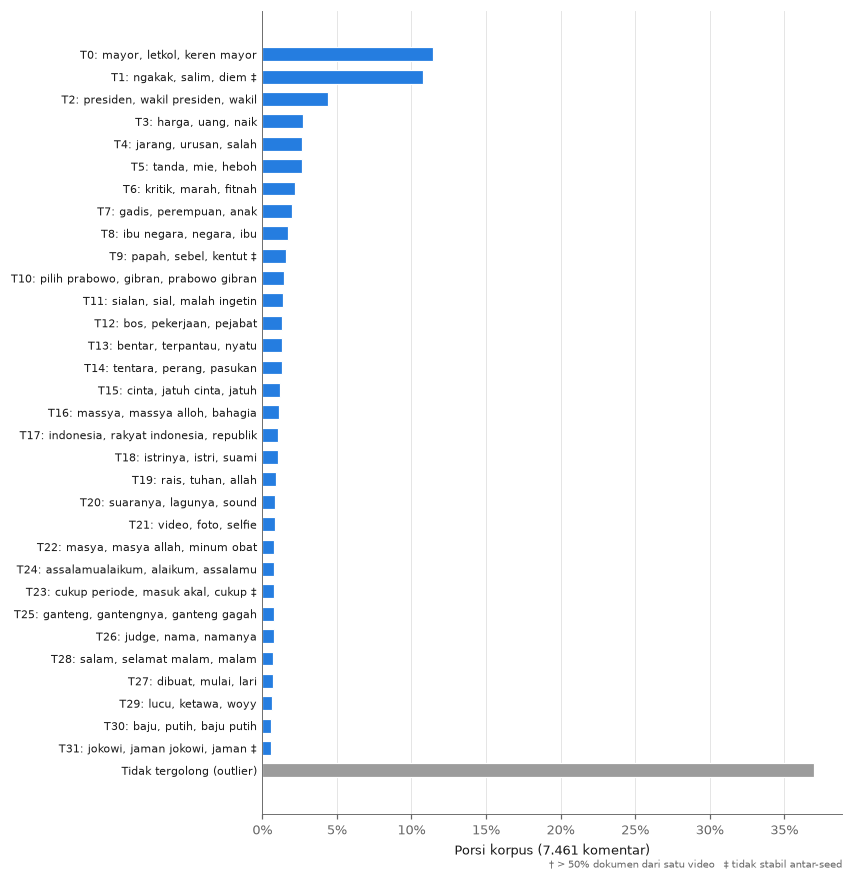

In [42]:
def gambar_prevalensi(tabel, kolom, nama, judul_x):
    d = tabel.sort_values("n")
    luar = d[kolom] == LUAR
    d = pd.concat([d[luar], d[~luar]])
    tanda = [nm + (" †" if nm != LUAR and v > AMBANG_DOMINASI_VIDEO else "") + (" ‡" if nm != LUAR and s < AMBANG_STABIL else "")
             for nm, v, s in zip(d[kolom], d["porsi_video_teratas"], d["stabilitas"])]
    fig, ax = plt.subplots(figsize=(6.8, 0.26 * len(d) + 0.9))
    ax.barh(range(len(d)), d["porsi"], height=0.62, color=[ABU if nm == LUAR else BIRU for nm in d[kolom]],
            edgecolor="white", linewidth=0.8)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels(tanda, fontsize=7.5, color=TEKS)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(fmt_persen)
    ax.set_xlabel(judul_x)
    ax.annotate(f"† > {persen(AMBANG_DOMINASI_VIDEO, 0)} dokumen dari satu video   ‡ tidak stabil antar-seed",
                xy=(1, 0), xycoords="axes fraction", xytext=(0, -30), textcoords="offset points",
                ha="right", va="top", fontsize=6.5, color=TEKS2)
    simpan_gambar(fig, nama)
    plt.show()

judul = f"Porsi korpus ({angka(len(korpus))} komentar)"
gambar_prevalensi(per_label, "label", "topik_gambar1_prevalensi", judul)
if ADA_KELOMPOK:
    gambar_prevalensi(per_kelompok, "kelompok", "topik_gambar1b_kelompok", judul)

Disimpan: outputs/tables/topik_04_bulanan.csv
Disimpan: outputs/figures/topik_gambar2_bulanan.png dan .pdf


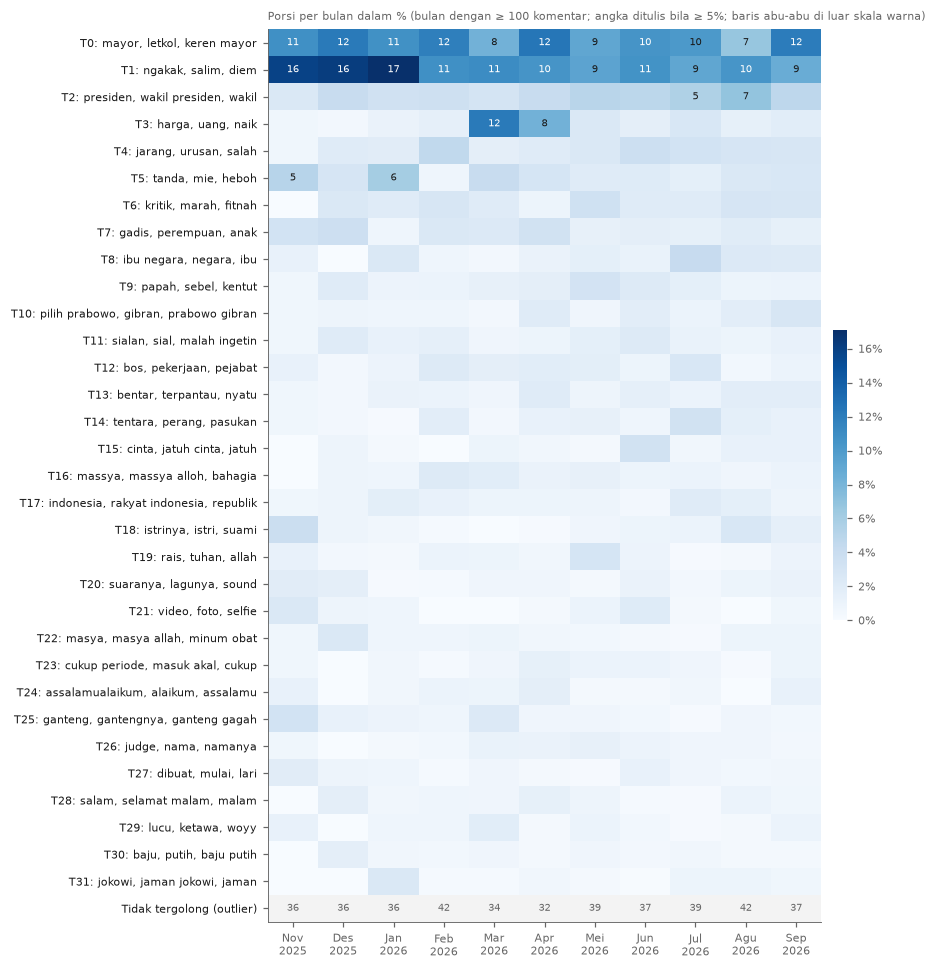

In [43]:
korpus["bulan"] = korpus["created_at"].dt.tz_localize(None).dt.to_period("M")
n_bulan = korpus.groupby("bulan").size()
bulan_ok = n_bulan[n_bulan >= AMBANG_BULAN].index
R["bulan_ditampilkan"] = [str(b) for b in bulan_ok]

def tabel_bulanan(kolom):
    tab = pd.crosstab(korpus[kolom], korpus["bulan"], normalize="columns")[bulan_ok]
    urut = [u for u in korpus[kolom].value_counts().index if u != LUAR]
    return tab.reindex(urut + ([LUAR] if LUAR in tab.index else []))

def simpan_bulanan(tab, kolom, nama):
    out = tab.round(4)
    out.columns = [str(c) for c in out.columns]
    out.loc["n_dokumen"] = n_bulan[bulan_ok].values
    simpan_tabel(out.rename_axis(kolom).reset_index(), nama)

def gambar_bulanan(tab, nama):
    M = tab.to_numpy(dtype=float)
    luar = np.array([i == LUAR for i in tab.index])
    Mp = M.copy()
    Mp[luar, :] = np.nan                      # baris outlier tidak ikut menentukan skala warna
    vmax = max(0.05, float(np.nanmax(Mp)))
    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("#f3f3f3")
    fig, ax = plt.subplots(figsize=(6.8, 0.28 * len(tab) + 1.3))
    im = ax.imshow(np.ma.masked_invalid(Mp), aspect="auto", cmap=cmap, vmin=0, vmax=vmax)
    ax.set_yticks(range(len(tab)))
    ax.set_yticklabels(tab.index, fontsize=7.5, color=TEKS)
    ax.set_xticks(range(len(bulan_ok)))
    ax.set_xticklabels([f"{NAMA_BULAN[b.month - 1]}\n{b.year}" for b in bulan_ok], fontsize=7)
    ax.grid(False)
    semua = len(tab) <= 12
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            if luar[i]:
                ax.text(j, i, angka(100 * v), ha="center", va="center", fontsize=6.5, color=TEKS2)
            elif semua or v >= 0.05:
                ax.text(j, i, angka(100 * v), ha="center", va="center", fontsize=6.5, color="white" if v > 0.6 * vmax else TEKS)
    cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, format=fmt_persen)
    cb.ax.tick_params(labelsize=7)
    cb.outline.set_visible(False)
    ket = "semua angka ditulis" if semua else "angka ditulis bila ≥ 5%"
    ax.set_title(f"Porsi per bulan dalam % (bulan dengan ≥ {AMBANG_BULAN} komentar; {ket}; baris abu-abu di luar skala warna)",
                 fontsize=7.5, color=TEKS2, loc="left")
    simpan_gambar(fig, nama)
    plt.show()

tab_label = tabel_bulanan("label")
simpan_bulanan(tab_label, "label", "topik_04_bulanan")
if ADA_KELOMPOK:
    tab_kelompok = tabel_bulanan("kelompok")
    simpan_bulanan(tab_kelompok, "kelompok", "topik_04b_bulanan_kelompok")
gambar_bulanan(tab_kelompok if ADA_KELOMPOK else tab_label, "topik_gambar2_bulanan")

Pergeseran porsi antarbulan **tidak otomatis** berarti pergeseran wacana publik. Komentar mengikuti video (Notebook 02: sebagian besar
ditulis beberapa hari setelah video diunggah), jadi bulan yang didominasi segelintir video akan didominasi topik video itu.
Bulan dengan dokumen sedikit juga goyah: pada 150–250 dokumen, satu komentar sudah bernilai 0,4–0,7 poin persen.

## A7. Topik × sentimen (bila prediksi sentimen tersedia)

Prediksi berasal dari model terbaik hasil evaluasi Kania. Kesalahan model ikut terbawa ke tabel ini; laporkan bersama macro-F1 model
dan jangan menafsirkan sel dengan n kecil. **Negatif tidak sama dengan kritik terhadap figur**: komentar negatif juga bisa berupa
serangan pendukung kepada pengkritik, rasa kasihan, atau keluhan umum. Karena itu label topik tetap ditentukan dari pembacaan.

In [44]:
SENTIMEN = None
if SENTIMEN_PATH.exists():
    pred = pd.read_parquet(SENTIMEN_PATH) if SENTIMEN_PATH.suffix == ".parquet" else pd.read_csv(SENTIMEN_PATH, dtype={"item_id": str})
    assert {"item_id", SENTIMEN_KOLOM} <= set(pred.columns), f"File prediksi harus punya kolom item_id dan {SENTIMEN_KOLOM}"
    pred["item_id"] = pred["item_id"].astype("string")
    pred = pred.drop_duplicates("item_id")
    korpus = korpus.merge(pred[["item_id", SENTIMEN_KOLOM]].rename(columns={SENTIMEN_KOLOM: "sentimen"}), on="item_id", how="left")
    cakupan = float(korpus["sentimen"].notna().mean())
    R["sentimen"] = {"file": SENTIMEN_PATH.name, "cakupan_join": round(cakupan, 4),
                     "distribusi_korpus": korpus["sentimen"].value_counts(normalize=True).round(4).to_dict()}
    print(f"Prediksi sentimen tergabung untuk {persen(cakupan)} korpus.")
    if cakupan < 0.95:
        print("PERINGATAN: < 95% komentar korpus punya prediksi. Cek apakah Kania memprediksi semua komentar eligible.")
    SENTIMEN = korpus["sentimen"]
else:
    print(f"File prediksi sentimen belum ada ({SENTIMEN_PATH.relative_to(ROOT) if SENTIMEN_PATH.is_relative_to(ROOT) else SENTIMEN_PATH}). "
          "A7 dan tahap B dilewati.")

File prediksi sentimen belum ada (data\processed\prediksi_sentimen.csv). A7 dan tahap B dilewati.


In [45]:
def urut_sentimen(nilai):
    def kunci(v):
        s = str(v).lower()
        return 0 if "neg" in s else (2 if "pos" in s else 1)
    return sorted(nilai, key=kunci)

def warna_sentimen(v):
    s = str(v).lower()
    return MERAH if "neg" in s else (BIRU if "pos" in s else "#b8b8b8")

def silang_sentimen(kolom):
    ada = korpus["sentimen"].notna()
    ts = pd.crosstab(korpus.loc[ada, kolom], korpus.loc[ada, "sentimen"])
    return ts[urut_sentimen(ts.columns)]

def simpan_sentimen(ts, kolom, nama):
    prop = ts.div(ts.sum(axis=1), axis=0)
    simpan_tabel(prop.round(4).add_prefix("porsi_").assign(n=ts.sum(axis=1)).rename_axis(kolom).reset_index(), nama)

def gambar_sentimen(ts, nama):
    n = ts.sum(axis=1)
    urutan = [LUAR] * (LUAR in ts.index) + [k for k in n.sort_values().index if k != LUAR]
    prop = ts.div(n, axis=0).reindex(urutan)
    fig, ax = plt.subplots(figsize=(6.8, 0.26 * len(prop) + 1.0))
    kiri = np.zeros(len(prop))
    for s in prop.columns:
        ax.barh(range(len(prop)), prop[s].values, left=kiri, height=0.62, color=warna_sentimen(s),
                edgecolor="white", linewidth=0.8, label=str(s))
        kiri += prop[s].values
    ax.set_yticks(range(len(prop)))
    ax.set_yticklabels([f"{k} (n={n[k]})" for k in prop.index], fontsize=7.5, color=TEKS)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(fmt_persen)
    ax.set_xlabel("Porsi komentar menurut prediksi sentimen")
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=len(prop.columns), handlelength=1.2)
    simpan_gambar(fig, nama)
    plt.show()

if SENTIMEN is not None:
    ts_label = silang_sentimen("label")
    simpan_sentimen(ts_label, "label", "topik_05_sentimen")
    if ADA_KELOMPOK:
        ts_kelompok = silang_sentimen("kelompok")
        simpan_sentimen(ts_kelompok, "kelompok", "topik_05b_sentimen_kelompok")
    gambar_sentimen(ts_kelompok if ADA_KELOMPOK else ts_label, "topik_gambar3_sentimen")

## B. Model terfokus: komentar yang diprediksi negatif

Embedding yang sama dipakai ulang (tidak dihitung lagi), tetapi UMAP dan HDBSCAN dilatih ulang hanya pada subset negatif, sehingga
tema yang jarang di korpus penuh bisa membentuk klaster sendiri. Pemeriksaan yang sama (dominasi video, stabilitas, teks identik)
diterapkan. Lembar tinjau: `data/processed/topik_tinjau_negatif.xlsx`; label: `config/topik_label_negatif.csv` (kolom sama dengan A5).

Saat memberi label, pisahkan setidaknya: kritik terhadap figur atau jabatannya, serangan atau pembelaan terhadap pihak lain,
dan negatif yang bukan kritik (sedih, kasihan, keluhan umum). Hanya kelompok pertama yang menjawab "tema kritik".

In [46]:
if SENTIMEN is not None:
    neg_lbl = LABEL_NEGATIF or next((v for v in korpus["sentimen"].dropna().unique() if "neg" in str(v).lower()), None)
    m_neg = (korpus["sentimen"] == neg_lbl).to_numpy() if neg_lbl is not None else np.zeros(len(korpus), bool)
    R["model_negatif"] = {"label_negatif": None if neg_lbl is None else str(neg_lbl), "n": int(m_neg.sum())}
    if m_neg.sum() < MIN_DOK_NEGATIF:
        print(f"Komentar negatif di korpus hanya {int(m_neg.sum())} (< {MIN_DOK_NEGATIF}); tahap B dilewati. "
              "Tema kritik cukup dibaca dari topik dengan porsi negatif tinggi di A7.")
    else:
        emb_n, teks_n, video_n = emb[m_neg], TEKS_NORM[m_neg], VIDEO[m_neg]
        tokens_n = [TOKENS[i] for i in np.flatnonzero(m_neg)]
        kamus_n = Dictionary(tokens_n)
        vocab_n = kosakata(teks_n, min_df=3)
        red_n = reduksi(emb_n, SEED)
        hasil_n, grid_n = jalankan_grid(teks_n, red_n, GRID_MCS_NEGATIF, video_n, tokens_n, kamus_n, vocab_n)
        (MCS_N, METODE_N), alasan_n = pilih(grid_n, KONFIG_TERPILIH_NEGATIF, batas_k=(3, 25))
        grid_n["terpilih"] = (grid_n["min_cluster_size"] == MCS_N) & (grid_n["metode"] == METODE_N)
        simpan_tabel(grid_n, "topik_06_grid_negatif")

        tm_n, topik_n = hasil_n[(MCS_N, METODE_N)]
        info_n = per_topik(topik_n, video_n, teks_n)
        _, npmi_n = coherence(tm_n, topik_n, tokens_n, kamus_n)
        info_n["npmi"] = info_n["topik"].map(npmi_n).round(4)
        info_n["kata_kunci"] = info_n["topik"].map(lambda t: ", ".join(w for w, _ in (tm_n.get_topic(t) or [])[:10]) if t != -1 else "")
        stab_n = [jaccard_terbaik(topik_n, latih(teks_n, reduksi(emb_n, s), MCS_N, METODE_N, vocab_n)[1]) for s in SEED_STABILITAS]
        info_n["stabilitas_jaccard"] = info_n["topik"].map(
            lambda t: np.mean([d.get(t, np.nan) for d in stab_n]) if t != -1 else np.nan).round(3)
        info_n["porsi_korpus"] = (info_n["n"] / int(m_neg.sum())).round(4)
        with pd.ExcelWriter(PRIVAT / "topik_tinjau_negatif.xlsx") as xw:
            info_n.to_excel(xw, sheet_name="Topik", index=False)
            contoh_topik(topik_n, emb_n, teks_asli[m_neg]).to_excel(xw, sheet_name="Contoh", index=False)
        print("Lembar tinjau (privat): data/processed/topik_tinjau_negatif.xlsx")
        LABEL_N = kelola_label(info_n, KONFIG / "topik_label_negatif.csv")
        info_n = terapkan_label(info_n, LABEL_N)
        per_label_n, _, _ = ringkas_label(info_n, topik_n, video_n, int(m_neg.sum()))
        kolom_n = ["topik", "label", "kelompok", "n", "porsi_korpus", "kata_kunci", "npmi", "n_video", "porsi_video_teratas",
                   "porsi_teks_unik", "stabilitas_jaccard"]
        simpan_tabel(info_n[kolom_n], "topik_07_info_negatif")
        simpan_tabel(per_label_n, "topik_07b_label_negatif")
        isi_n = info_n[info_n["topik"] != -1]
        R["model_negatif"].update({
            "min_cluster_size": MCS_N, "metode": METODE_N, "alasan": alasan_n, "k_topik": int(len(isi_n)),
            "porsi_outlier": round(float((topik_n == -1).mean()), 4),
            "topik_dominasi_satu_video": int((isi_n["porsi_video_teratas"] > AMBANG_DOMINASI_VIDEO).sum()),
            "topik_tidak_stabil": int((isi_n["stabilitas_jaccard"] < AMBANG_STABIL).sum()),
            "topik_berlabel_manual": len(LABEL_N),
        })
        gambar_prevalensi(per_label_n, "label", "topik_gambar4_negatif", f"Porsi komentar negatif ({angka(int(m_neg.sum()))} komentar)")
        display(grid_n)
        display(info_n[kolom_n])

## Ringkasan angka dan lingkungan

In [47]:
import importlib.metadata as im

def versi(p):
    try:
        return im.version(p)
    except im.PackageNotFoundError:
        return None

def ke_json(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, dict):
        return {str(k): ke_json(x) for k, x in o.items()}
    if isinstance(o, (list, tuple)):
        return [ke_json(x) for x in o]
    return o

R["lingkungan"] = {"model_embedding": MODEL_EMBEDDING,
                   **{p: versi(p) for p in ("bertopic", "umap-learn", "hdbscan", "sentence-transformers", "gensim", "scikit-learn")}}
R["dibuat_dari"] = DATA.name
(TAB / "topik_ringkasan.json").write_text(json.dumps(ke_json(R), ensure_ascii=False, indent=2), encoding="utf-8")
print("Disimpan: outputs/tables/topik_ringkasan.json")
print(json.dumps(ke_json({k: R[k] for k in ("korpus", "pemilihan", "model_umum")}), ensure_ascii=False, indent=2))

Disimpan: outputs/tables/topik_ringkasan.json
{
  "korpus": {
    "Komentar eligible": 9350,
    "Dibuang: tanpa kata berhuruf": 401,
    "Dibuang: 1 s.d. 2 kata": 1488,
    "Korpus topic modeling": 7461
  },
  "pemilihan": {
    "min_cluster_size": 40,
    "metode": "eom",
    "alasan": "dipilih manual lewat KONFIG_TERPILIH",
    "min_samples": 10,
    "umap": {
      "n_neighbors": 15,
      "n_components": 5,
      "min_dist": 0.0,
      "metric": "cosine"
    },
    "seed": 42,
    "batas": {
      "outlier": 0.5,
      "k": [
        5,
        40
      ],
      "topik_terbesar": 0.35
    }
  },
  "model_umum": {
    "k_topik": 32,
    "porsi_outlier": 0.3702,
    "npmi_rata2": -0.2911,
    "diversity": 0.9375,
    "ari_antar_seed": [
      0.709,
      0.7
    ],
    "topik_dominasi_satu_video": 0,
    "topik_tidak_stabil": 4,
    "topik_banyak_teks_identik": 0,
    "topik_berlabel_manual": 0,
    "jumlah_label_akhir": 32,
    "kelompok_terisi": false
  }
}


## Catatan untuk penulisan (metode dan hasil topik)

- **Metode (3.2):** sebutkan unit (komentar eligible ≥ `MIN_KATA` kata, dengan jumlah dari `topik_01_korpus`), model embedding,
  UMAP sekali dengan seed tetap, grid `min_cluster_size` × metode klaster dan aturan pemilihannya, kosakata c-TF-IDF (stopword, nama figur dibuang,
  pangkat/jabatan dipertahankan), pemeriksaan kualitas (dominasi video, stabilitas, teks identik), dan pelabelan manual oleh dua orang.
- **Hasil:** laporkan jumlah topik (sebelum dan sesudah penggabungan label) dan **porsi outlier**, lalu kelompok dan topik terbesar
  dengan porsinya. Topik berlabel `Campuran` disebut jumlahnya tetapi tidak ditafsirkan sebagai tema. Topik bertanda † atau ‡ disebut
  sebagai demikian. Contoh komentar ditulis sebagai parafrase.
- **Tema kritik:** dukung dengan A7 (porsi negatif per topik) dan, bila tersedia, tahap B. Nyatakan bahwa negatif ≠ kritik dan bahwa
  angka mewarisi kesalahan model sentimen.
- **Batasan:** komentar pendek, cakupan pengambilan kecil (Notebook 01), topik yang terikat video, dan kepekaan terhadap seed (ARI).
- **Netral:** label topik menggambarkan isi wacana, bukan menilai figur atau pengguna.